In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

X = np.sort(10 * np.random.rand(1000, 1), axis=0)

y = np.sin(X).ravel() + np.random.normal(0, 0.2, X.shape[0])

print(f"Згенеровано {X.shape[0]} значень X та {y.shape[0]} значень y.")

Згенеровано 1000 значень X та 1000 значень y.


In [3]:
scaler = StandardScaler()
X_normalized = scaler.fit_transform(X)

print(f"Середнє після нормалізації: {np.mean(X_normalized):.2f}")
print(f"Дисперсія після нормалізації: {np.var(X_normalized):.2f}")

Середнє після нормалізації: 0.00
Дисперсія після нормалізації: 1.00


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.2, random_state=42
)

print(f"Розмір навчальної вибірки: {X_train.shape[0]}")
print(f"Розмір тестової вибірки: {X_test.shape[0]}")

Розмір навчальної вибірки: 800
Розмір тестової вибірки: 200


In [5]:
k_values = range(1, 51)
mse_scores = []
models = {}

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    mse_scores.append(mse)
    models[k] = knn

best_k = k_values[np.argmin(mse_scores)]
best_model = models[best_k]

print(f"Найкраще значення K: {best_k}")
print(f"Мінімальна середньоквадратична помилка (MSE) на тестовій вибірці: {min(mse_scores):.4f}")

Найкраще значення K: 22
Мінімальна середньоквадратична помилка (MSE) на тестовій вибірці: 0.0355


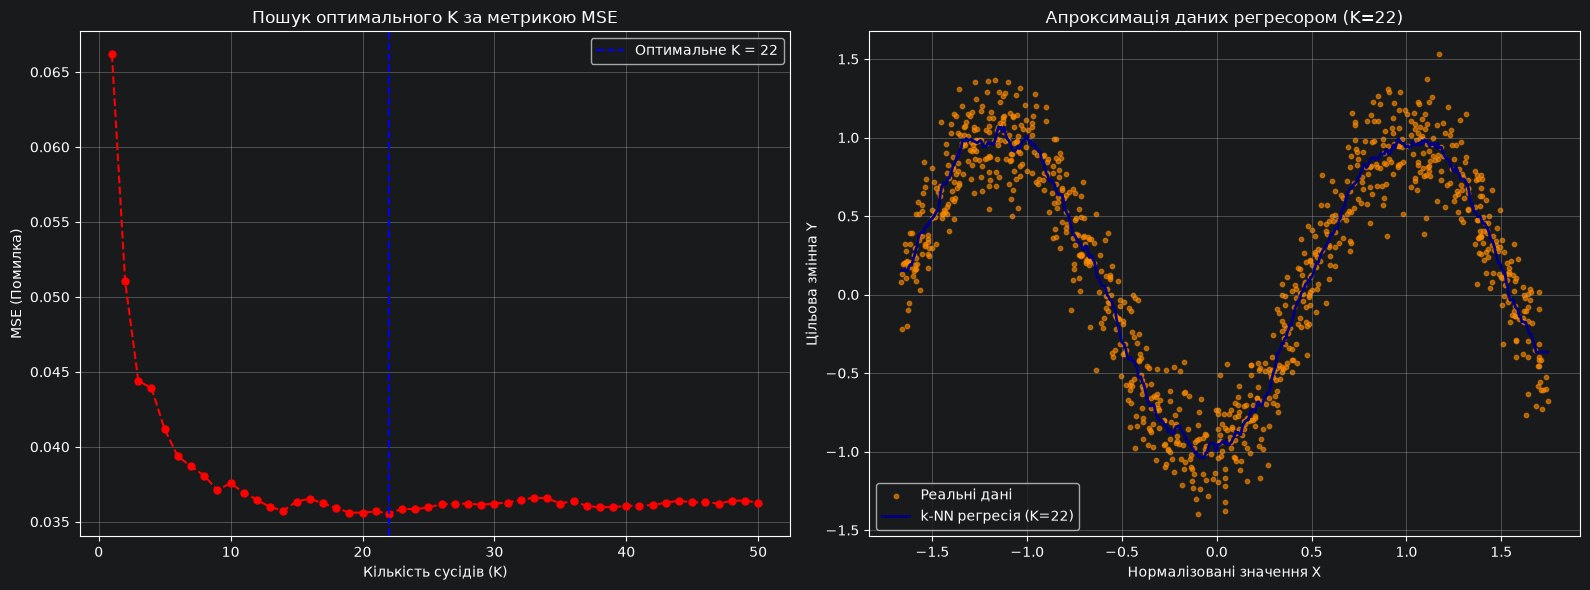

In [6]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.plot(k_values, mse_scores, marker='o', linestyle='dashed', color='red', markersize=5)
plt.axvline(x=best_k, color='blue', linestyle='--', label=f'Оптимальне K = {best_k}')
plt.title('Пошук оптимального K за метрикою MSE')
plt.xlabel('Кількість сусідів (K)')
plt.ylabel('MSE (Помилка)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(X_normalized, y, color='darkorange', label='Реальні дані', s=10, alpha=0.6)

T_axis = np.linspace(X_normalized.min(), X_normalized.max(), 500)[:, np.newaxis]
y_pred_best = best_model.predict(T_axis)

plt.plot(T_axis, y_pred_best, color='navy', label=f'k-NN регресія (K={best_k})', linewidth=2)
plt.title(f'Апроксимація даних регресором (K={best_k})')
plt.xlabel('Нормалізовані значення X')
plt.ylabel('Цільова змінна Y')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()